In [3]:
!pip install ipython-sql
!pip install pandas
!pip install ipython-sql prettytable


import csv, sqlite3, prettytable
import pandas
con = sqlite3.connect("credit_card_fraud.db")
cur = con.cursor()
prettytable.DEFAULT = 'DEFAULT'


In [4]:
# The %load_ext sql enables the %sql and %%sql magic commands
# Connect to the SQLite database file 'credit_card_fraud.db' in the current directory
# After this, you can run SQL queries directly in the notebook, e.g.:
#   %sql SELECT * FROM Credit_Card_Fraud_Data LIMIT 5
%load_ext sql
%sql sqlite:///credit_card_fraud.db

In [5]:
# Read the CSV file into a pandas DataFrame and then Write the DataFrame to a SQLite table named 'Credit_Card_Fraud_Data'
# - con: the SQLite connection object (created via sqlite3.connect())
# - if_exists='replace': drop the table if it already exists, then recreate it
# - index=False: do not write the DataFrame index as a column

df = pandas.read_csv('credit_card_fraud_detection_2026.csv')
df.to_sql('Credit_Card_Fraud_Data',con,if_exists='replace',index=False)

100000

In [6]:
#shows how many rows and collumns in the data
df.shape

(100000, 43)

In [7]:
# Missing values: only 'browser' has 41,709 nulls (~X% of rows)
# No impact on fraud analysis (browser not used in queries)
df.isnull().sum()

transaction_id                     0
customer_id                        0
card_id                            0
merchant_id                        0
transaction_datetime               0
transaction_amount                 0
merchant_category                  0
merchant_country                   0
transaction_hour                   0
transaction_day_of_week            0
card_present                       0
customer_age                       0
customer_gender                    0
customer_state                     0
account_age_days                   0
credit_limit                       0
credit_score                       0
num_cards_held                     0
transactions_last_1h               0
transactions_last_24h              0
transactions_last_7d               0
amount_last_1h                     0
amount_last_24h                    0
days_since_last_transaction        0
distance_from_home_km              0
distance_from_last_tx_km           0
international_transaction          0
h

In [8]:
df.describe()

,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,...,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud,fraud_amount_lost
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,126.871977,14.393860,0.357770,42.223670,785.451240,10083.182000,682.329280,2.198830,0.783890,2.951760,...,1.959943,0.314790,0.18387,0.284130,124.402467,68.462010,0.512860,0.366930,0.020550,2.798422
std,276.180425,5.018253,0.479346,14.246361,747.492434,6510.646682,92.122179,1.163491,1.348801,2.382417,...,6.370778,0.464435,0.38738,0.451001,119.714229,70.828223,1.007673,0.785773,0.141873,43.669579
min,0.500000,0.000000,0.000000,18.000000,1.000000,500.000000,328.000000,1.000000,0.000000,0.000000,...,0.001000,0.000000,0.00000,0.000000,5.380000,2.460000,0.000000,0.000000,0.000000,0.000000
25%,21.280000,11.000000,0.000000,32.000000,233.000000,5000.000000,620.000000,1.000000,0.000000,1.000000,...,0.206000,0.000000,0.00000,0.000000,52.460000,26.880000,0.000000,0.000000,0.000000,0.000000
50%,52.260000,14.000000,0.000000,42.000000,554.000000,8500.000000,683.000000,2.000000,0.000000,2.000000,...,0.584000,0.000000,0.00000,0.000000,89.370000,48.170000,0.000000,0.000000,0.000000,0.000000
75%,129.720000,19.000000,1.000000,52.000000,1103.000000,13650.000000,748.000000,3.000000,1.000000,4.000000,...,1.660250,1.000000,0.00000,1.000000,155.080000,85.420000,1.000000,0.000000,0.000000,0.000000
max,15000.000000,23.000000,1.000000,85.000000,3650.000000,36670.000000,850.000000,5.000000,8.000000,18.000000,...,686.322000,1.000000,1.00000,1.000000,2000.000000,1334.920000,5.000000,4.000000,1.000000,4482.160000


In [9]:
%sql PRAGMA table_info('Credit_Card_Fraud_Data');  

 * sqlite:///credit_card_fraud.db
Done.


cid,name,type,notnull,dflt_value,pk
0,transaction_id,TEXT,0,None,0
1,customer_id,TEXT,0,None,0
2,card_id,TEXT,0,None,0
3,merchant_id,TEXT,0,None,0
4,transaction_datetime,TEXT,0,None,0
5,transaction_amount,REAL,0,None,0
6,merchant_category,TEXT,0,None,0
7,merchant_country,TEXT,0,None,0
8,transaction_hour,INTEGER,0,None,0
9,transaction_day_of_week,TEXT,0,None,0


In [10]:
# Run a SQL query against the connected database (credit_card_fraud.db)
# - Selects three columns: fraud_amount_lost, customer_age, customer_gender
# - Filters rows where fraud_amount_lost > 0.0 (only actual fraud losses)
# - Orders by fraud_amount_lost in descending order (largest losses first)
# - LIMIT 5: returns only the top 5 rows
# - The trailing backslash (\) is a line continuation (not needed on a single line)
%sql SELECT fraud_amount_lost, customer_age, customer_gender FROM Credit_Card_Fraud_Data WHERE fraud_amount_lost > 0.0 ORDER BY fraud_amount_lost DESC LIMIT 5   
%sql SELECT fraud_amount_lost,customer_age,customer_gender FROM Credit_Card_Fraud_Data where fraud_amount_lost>0.0\
GROUP BY customer_age\
ORDER BY fraud_amount_lost desc LIMIT 20

 * sqlite:///credit_card_fraud.db
Done.
 * sqlite:///credit_card_fraud.db
Done.


fraud_amount_lost,customer_age,customer_gender
1593.14,50,Male
1016.23,26,Female
910.84,75,Female
901.92,48,Male
665.79,67,Female
600.04,76,Female
586.44,49,Female
561.59,21,Male
501.72,73,Male
466.01,28,Female


In [11]:
%sql SELECT customer_state FROM Credit_Card_Fraud_Data LIMIT 5

 * sqlite:///credit_card_fraud.db
Done.


customer_state
PA
WV
MN
OH
PA


In [12]:
# Group by customer_gender, sum the fraud losses per gender,
# sort descending, and puts the gender that lost the most at the top
%sql SELECT customer_gender, SUM(fraud_amount_lost) AS total_lost \
     FROM Credit_Card_Fraud_Data \
     WHERE fraud_amount_lost > 0.0 \
     GROUP BY customer_gender \
     ORDER BY total_lost DESC 

 * sqlite:///credit_card_fraud.db
Done.


customer_gender,total_lost
Female,141023.69
Male,130769.74
Other,8048.77


In [13]:
# Calculate the average fraud loss per event, grouped by gender
# - Only considers rows where actual money was lost (> 0.0)
# - Orders by average loss descending (highest avg first)
# - Shows which gender suffers the largest average loss per fraud event
%sql SELECT customer_gender, AVG(fraud_amount_lost) AS avg_lost \
     FROM Credit_Card_Fraud_Data \
     WHERE fraud_amount_lost > 0.0 \
    GROUP BY customer_gender \
    ORDER BY avg_lost DESC
         

 * sqlite:///credit_card_fraud.db
Done.


customer_gender,avg_lost
Other,191.63738095238097
Female,135.46944284341978
Male,134.53676954732512


In [14]:
# Calculate the average fraud loss per event, grouped by state
# - Only considers rows where actual money was lost (> 0.0)
# - Orders by average loss descending (highest avg first)
# - Shows which state suffers the largest average loss per fraud event LIMIT 10(limits it to 10 states)
%sql SELECT customer_state, AVG(fraud_amount_lost) AS avg_lost \
     FROM Credit_Card_Fraud_Data \
     WHERE fraud_amount_lost > 0.0 \
    GROUP BY customer_state \
    ORDER BY avg_lost DESC LIMIT 10

 * sqlite:///credit_card_fraud.db
Done.


customer_state,avg_lost
LA,328.3607692307692
KY,211.90365853658534
AR,200.98613636363635
CT,197.35833333333332
MA,191.5488679245283
IA,177.15048387096775
UT,174.18714285714285
IL,166.39396551724138
NM,166.09622950819673
KS,162.03910714285715


In [15]:
# Calculate the average fraud loss per event, grouped by age
# - Only considers rows where actual money was lost (> 0.0)
# - Orders by average loss descending (highest avg first)
# - Shows the top 10 ages with the largest average loss per fraud event
%sql SELECT customer_age, AVG(fraud_amount_lost) AS avg_lost \
     FROM Credit_Card_Fraud_Data \
     WHERE fraud_amount_lost > 0.0 \
    GROUP BY customer_age \
    ORDER BY avg_lost DESC LIMIT 10

 * sqlite:///credit_card_fraud.db
Done.


customer_age,avg_lost
75,474.90500000000003
19,326.68454545454546
76,309.8875
49,264.48954545454546
24,256.06458333333336
23,209.51666666666665
78,208.95
50,208.73307692307694
48,201.0101886792453
52,199.55659090909091


In [16]:
# Count fraud events and calculate average loss per gender
# - Only considers rows where actual money was lost (> 0.0)
# - COUNT(*) gives the number of fraud events per gender (frequency)
# - AVG gives the average loss per event per gender (severity)
# - Orders by number of events descending (most-hit gender first)
%sql SELECT customer_gender,\
           COUNT(*) AS fraud_events,\
           AVG(fraud_amount_lost) AS avg_lost\
     FROM Credit_Card_Fraud_Data\
     WHERE fraud_amount_lost > 0.0\
     GROUP BY customer_gender\
     ORDER BY fraud_events DESC

 * sqlite:///credit_card_fraud.db
Done.


customer_gender,fraud_events,avg_lost
Female,1041,135.46944284341978
Male,972,134.53676954732512
Other,42,191.63738095238097


In [17]:
# Count fraud events and calculate average loss per state
# - Only considers rows where actual money was lost (> 0.0)
# - COUNT(*) gives the number of fraud events per state (frequency)
# - AVG gives the average loss per event per state (severity)
# - Orders by number of events descending (most-hit state first)
# - LIMIT 10: shows only the top 10 states by fraud frequency
%sql SELECT customer_state,\
           COUNT(*) AS fraud_events,\
           AVG(fraud_amount_lost) AS avg_lost\
     FROM Credit_Card_Fraud_Data\
     WHERE fraud_amount_lost > 0.0\
     GROUP BY customer_state\
     ORDER BY fraud_events DESC LIMIT 10

 * sqlite:///credit_card_fraud.db
Done.


customer_state,fraud_events,avg_lost
NE,77,124.77376623376624
SC,68,131.79279411764705
IA,62,177.15048387096775
NM,61,166.09622950819673
AZ,61,83.87196721311474
VA,60,132.3325
CO,59,145.0871186440678
IL,58,166.39396551724138
MN,57,97.73087719298245
OH,56,105.66553571428572


In [18]:
# Count fraud events and calculate average loss per day of the week
# - Only considers rows where actual money was lost (> 0.0)
# - COUNT(*) gives the number of fraud events per day (frequency)
# - AVG gives the average loss per event per day (severity)
# - Orders by number of events descending (most fraud on this day first)
# - Reveals whether fraud is concentrated on certain days (e.g., weekends)
%sql SELECT transaction_day_of_week,\
           COUNT(*) AS fraud_events,\
           AVG(fraud_amount_lost) AS avg_lost\
     FROM Credit_Card_Fraud_Data\
     WHERE fraud_amount_lost > 0.0\
     GROUP BY transaction_day_of_week\
     ORDER BY fraud_events DESC 

 * sqlite:///credit_card_fraud.db
Done.


transaction_day_of_week,fraud_events,avg_lost
Saturday,317,163.50738170347003
Tuesday,305,131.8540655737705
Wednesday,300,141.98086666666669
Thursday,292,154.85626712328767
Friday,286,117.59118881118881
Monday,279,132.91910394265233
Sunday,276,106.04010869565218


In [19]:
# Calculate the average fraud loss per event, grouped by day of the week
# - Only considers rows where actual money was lost (> 0.0)
# - Orders by average loss descending (highest avg first)
# - Shows which day of the week has the largest average loss per fraud event
%sql SELECT transaction_day_of_week,\
            AVG(fraud_amount_lost) AS avg_lost\
        FROM Credit_Card_Fraud_Data\
        WHERE fraud_amount_lost > 0.0\
        GROUP BY transaction_day_of_week\
        ORDER BY avg_lost DESC 

 * sqlite:///credit_card_fraud.db
Done.


transaction_day_of_week,avg_lost
Saturday,163.50738170347003
Thursday,154.85626712328767
Wednesday,141.98086666666669
Monday,132.91910394265233
Tuesday,131.8540655737705
Friday,117.59118881118881
Sunday,106.04010869565218


In [20]:
# Compare mean vs median to check for skew
df_fraud = df[df['fraud_amount_lost'] > 0]

print(f"Mean:   {df_fraud['fraud_amount_lost'].mean():.2f}")
print(f"Median: {df_fraud['fraud_amount_lost'].median():.2f}")   
# Mean vs median per state
df_fraud.groupby('customer_state')['fraud_amount_lost'].agg(['mean', 'median']).sort_values('mean', ascending=False).head(10)   

Mean:   136.18
Median: 50.09


,mean,median
customer_state,,
LA,328.360769,73.120
KY,211.903659,61.860
AR,200.986136,59.265
CT,197.358333,70.260
MA,191.548868,60.800
IA,177.150484,80.550
UT,174.187143,64.560
IL,166.393966,86.450
NM,166.096230,33.870


In [21]:
# Count fraud events and total loss per month
# - Extracts the month from the transaction_datetime column using strftime('%m', ...)
# - Only considers rows where actual money was lost (> 0.0)
# - COUNT(*) gives the number of fraud events per month (frequency)
# - SUM gives the total money lost per month (volume)
# - Orders by total loss descending (highest-impact month first)
# - Reveals seasonal patterns or spikes in fraud activity
%sql SELECT strftime('%m', transaction_datetime) AS month,\
       COUNT(*) AS fraud_events,\
       SUM(fraud_amount_lost) AS total_lost\
     FROM Credit_Card_Fraud_Data\
     WHERE fraud_amount_lost > 0.0\
     GROUP BY month\
     ORDER BY total_lost DESC

 * sqlite:///credit_card_fraud.db
Done.


month,fraud_events,total_lost
01,191,32358.42
11,175,30158.98
10,198,26000.04
12,177,24169.21
08,174,23184.77
06,153,23026.8
05,171,22662.32
03,164,22120.54
02,151,22091.11
07,181,20512.69


 * sqlite:///credit_card_fraud.db
 * sqlite:///credit_card_fraud.db
Done.


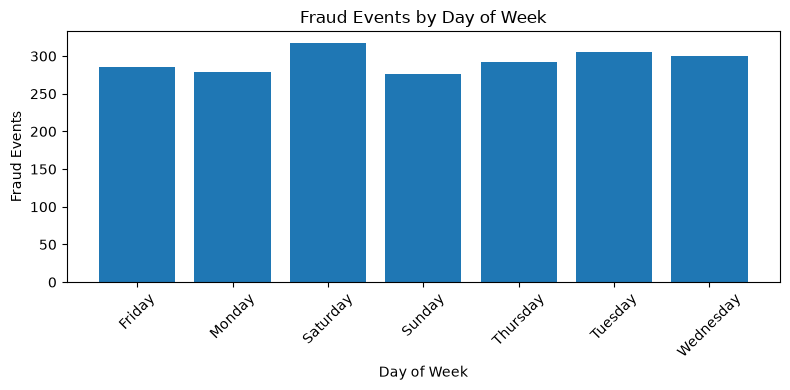

In [28]:
# Plot a bar chart of fraud events by day of the week
# - Queries the database for event counts per day (only actual fraud, loss > 0)
# - Converts the raw query result into a pandas DataFrame with named columns
# - Saves the chart as 'fraud_by_dow.png' for use in the README
# - Reveals whether fraud is concentrated on certain days (e.g., weekends vs weekdays)
import matplotlib.pyplot as plt
import pandas as pd

%sql --store

result = %sql SELECT transaction_day_of_week, COUNT(*) AS fraud_events\
             FROM Credit_Card_Fraud_Data WHERE fraud_amount_lost > 0.0\
             GROUP BY transaction_day_of_week ORDER BY transaction_day_of_week

df_dow = pd.DataFrame(result, columns=['transaction_day_of_week', 'fraud_events'])

plt.figure(figsize=(8, 4))
plt.bar(df_dow['transaction_day_of_week'], df_dow['fraud_events'])
plt.xlabel('Day of Week')
plt.ylabel('Fraud Events')
plt.title('Fraud Events by Day of Week')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fraud_by_dow.png')
plt.show()   

 * sqlite:///credit_card_fraud.db
 * sqlite:///credit_card_fraud.db
Done.


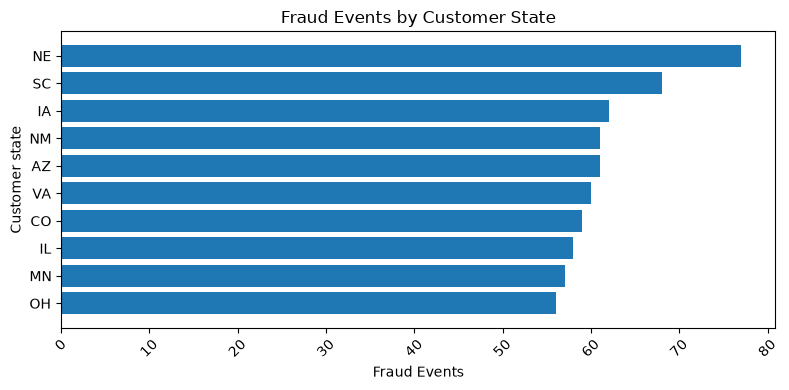

In [30]:
# Plot a horizontal bar chart of the top 10 states by fraud event count
# - Only actual fraud (loss > 0.0)
# - Reversed so the highest value appears at the top of the chart
# - Saves as 'fraud_by_state.png' for the README
%sql --store

result = %sql SELECT customer_state, COUNT(*) AS fraud_events\
             FROM Credit_Card_Fraud_Data WHERE fraud_amount_lost > 0.0\
             GROUP BY customer_state ORDER BY fraud_events DESC LIMIT 10

df_state = pd.DataFrame(result, columns=['customer_state', 'fraud_events'])

plt.figure(figsize=(8, 4))
plt.barh(df_state['customer_state'][::-1], df_state['fraud_events'][::-1])
plt.xlabel('Fraud Events')
plt.ylabel('Customer state')
plt.title('Fraud Events by Customer State')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fraud_by_customer_state.png')
plt.show()   

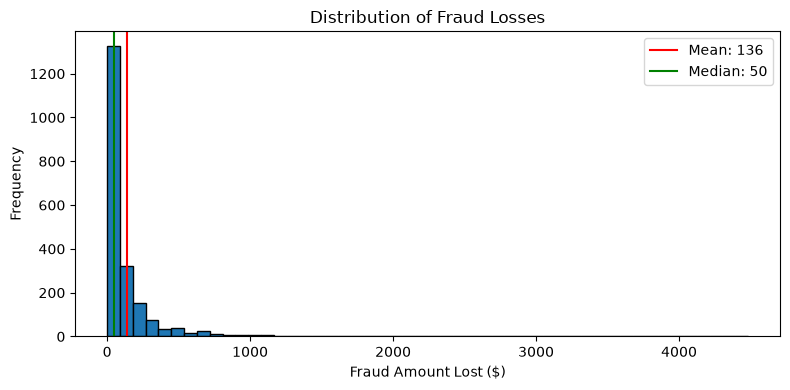

In [31]:
# Plot a histogram of fraud loss amounts with mean and median reference lines
# - Filters to only actual fraud events (loss > 0)
# - Red line = mean, green line = median
# - If mean >> median, the distribution is right-skewed (few huge outliers)
# - Saves as 'loss_distribution.png' for the README
df_fraud = df[df['fraud_amount_lost'] > 0]

plt.figure(figsize=(8, 4))
plt.hist(df_fraud['fraud_amount_lost'], bins=50, edgecolor='black')
plt.axvline(df_fraud['fraud_amount_lost'].mean(), color='red', label=f"Mean: {df_fraud['fraud_amount_lost'].mean():.0f}")
plt.axvline(df_fraud['fraud_amount_lost'].median(), color='green', label=f"Median: {df_fraud['fraud_amount_lost'].median():.0f}")
plt.xlabel('Fraud Amount Lost ($)')
plt.ylabel('Frequency')
plt.title('Distribution of Fraud Losses')
plt.legend()
plt.tight_layout()
plt.savefig('loss_distribution.png')
plt.show()   

 * sqlite:///credit_card_fraud.db
Done.


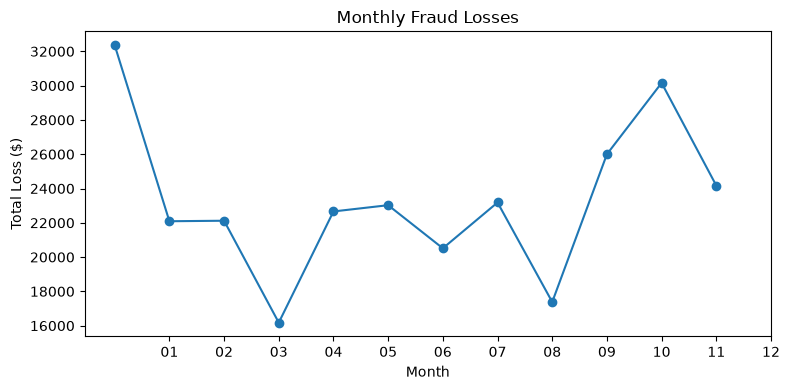

In [33]:
# Plot a line chart of total fraud loss per month
# - Extracts month from transaction_datetime using strftime
# - Only actual fraud (loss > 0.0)
# - Reveals seasonal patterns or spikes in fraud activity
# - Saves as 'fraud_by_month.png' for the README
result = %sql SELECT strftime('%m', transaction_datetime) AS month,\
                    SUM(fraud_amount_lost) AS total_lost\
             FROM Credit_Card_Fraud_Data WHERE fraud_amount_lost > 0.0\
             GROUP BY month ORDER BY month

df_month = pd.DataFrame(result, columns=['month', 'total_lost'])

plt.figure(figsize=(8, 4))
plt.plot(df_month['month'], df_month['total_lost'], marker='o')
plt.xlabel('Month')
plt.ylabel('Total Loss ($)')
plt.title('Monthly Fraud Losses')
plt.xticks(range(1, 13), [f"{m:02d}" for m in range(1, 13)])
plt.tight_layout()
plt.savefig('fraud_by_month.png')
plt.show()   